<a href="https://colab.research.google.com/github/itebaldi/cps783-metaheuristics/blob/main/metaheuristics/trabalho/Trabalho_MH_Grafos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho de Metaheurísticas — CFLP com grafos e GRASP + SA

O problema clássico de Localização de Facilidades Capacitadas (*Capacitated Facility Location Problem* = **CFLP**)
consiste em selecionar facilidades a serem abertas/construídas para atender clientes.
As restrições referem-se aos clientes, cuja demanda deve ser integralmente atendida,
e à capacidade das facilidades, que não pode ser excedida.
Consideraremos a versão de múltiplas fontes do problema, na qual
cada cliente pode ser atendido por mais de uma facilidade.
A função objetivo, que deve ser minimizada, consiste na soma dos custos fixos de abertura
das facilidades e dos custos variáveis de transporte (cliente, facilidade).

A este problema tradicional, adicionaremos a restrição de que certos pares de clientes
não podem ser atendidos pela mesma facilidade.
Essa restrição modela situações reais em que os clientes possuem demandas conflitantes
(por exemplo, componentes químicos que devem ficar bem longe um do outro).

Seja $J$ um conjunto de facilidades tal que cada facilidade $j \in J$ possua uma capacidade $C_j$
e um custo fixo $f_j$ de abertura/ativação.
Seja $I$ um conjunto de clientes tal que cada cliente $i \in I$ possui uma demanda $d_i$,
que deve ser totalmente atendida por uma ou mais facilidades.
Há também um custo $c_{ij}$, que representa o custo unitário de transportar mercadorias
da facilidade $j$ para o cliente $i$.
Por fim, é fornecido um conjunto $P$ de pares de clientes conflitantes.
Para cada $(i,k) \in P$,
os clientes $i$ e $k$ não podem ser atendidos pela mesma facilidade.

### Variáveis de decisão

- $x_{ij}$ é a quantidade inteira transportada da facilidade $j$ para o cliente $i$.
- $y_j$ vale $1$ quando a facilidade $j$ está aberta e $0$ quando está fechada.

### Função objetivo

$$
\min_{x,y}\; Z =
\underbrace{\sum_{j\in J} f_j\,y_j}_{\text{custo fixo de abertura}}
+
\underbrace{\sum_{i\in I}\sum_{j\in J} c_{ij}\,x_{ij}}_{\text{custo de transporte}}.
$$

### Restrições

**Atendimento integral da demanda**

$$
\sum_{j\in J} x_{ij} = d_i
\qquad \forall\, i\in I.
$$

**Capacidade e abertura das facilidades**

$$
\sum_{i\in I} x_{ij} \le C_j\,y_j
\qquad \forall\, j\in J.
$$

**Conflitos entre clientes**

$$
x_{ij} = 0 \quad \text{ou} \quad x_{kj} = 0
\qquad \forall\, (i,k)\in P,\ \forall\, j\in J.
$$

**Domínio das variáveis**

$$
\begin{aligned}
0 \le x_{ij} \le d_i,\quad x_{ij}\in\mathbb{Z}
&\qquad \forall\, i\in I,\ \forall\, j\in J,\\
y_j\in\{0,1\}
&\qquad \forall\, j\in J.
\end{aligned}
$$

Todos os valores de entrada são inteiros não negativos.

### Representação no código

- `instance.n_clientes` e `instance.n_facilidades` guardam as quantidades de clientes e facilidades (são os `instance.I` e `instance.J` da classe da professora).
- `alocacao[cliente, facilidade]` corresponde a $x_{ij}$. As linhas representam clientes, e as colunas, facilidades.
- `abertas[facilidade]` corresponde a $y_j$. No Python, os índices de clientes e facilidades começam em zero.

## Preparação

Todo o código do trabalho está neste notebook. No Colab, a célula abaixo baixa a instância toy do repositório público da dupla. No VS Code, ela usa o `tests/trabalho/toy.txt` do repositório.

Todos os métodos aceitam um parâmetro opcional `debug`, que desenha uma figura por iteração. Este notebook não usa o `debug` e não depende dele: os métodos só o chamam quando ele é passado. Para ver o que um método faz, rode o teste `tests/trabalho/test_debug_metodos.py` com `PLOT = True`. Ele executa as células deste notebook, menos as marcadas com a tag `experimento` (comparação, gráficos e testes), e passa aos métodos o `Debug` de `metaheuristics/trabalho/debug.py`.

In [1]:
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    pasta_toy = Path("/content/toy_repo")
    if not pasta_toy.exists():
        subprocess.run(
            [
                "git",
                "clone",
                "https://github.com/diasluciana/toy_txt_metaheuristica.git",
                str(pasta_toy),
            ],
            check=True,
        )
    CAMINHO_INSTANCIA = pasta_toy / "toy.txt"
    DIRETORIO_GRAFICOS = Path("/content")
else:
    # Raiz do repositório: a primeira pasta, subindo, que tem o pyproject.toml
    RAIZ_REPOSITORIO = next(
        pasta
        for pasta in (Path.cwd(), *Path.cwd().parents)
        if (pasta / "pyproject.toml").exists()
    )
    CAMINHO_INSTANCIA = RAIZ_REPOSITORIO / "tests" / "trabalho" / "toy.txt"
    DIRETORIO_GRAFICOS = RAIZ_REPOSITORIO / "plots" / "trabalho"

In [2]:
import random
import re
from collections.abc import Iterable
from collections.abc import Sequence
from itertools import combinations

import numpy as np
import numpy.typing as npt

# alocacao[cliente, facilidade]: uma linha por cliente, uma coluna por facilidade
Matriz = npt.NDArray[np.int_]
# abertas[facilidade], capacidades, demandas
Vetor = npt.NDArray[np.int_]


class Instance:
    def __init__(
        self,
        n_facilidades: int,
        n_clientes: int,
        capacidades: npt.ArrayLike,
        custos_fixos: npt.ArrayLike,
        demandas: npt.ArrayLike,
        custos_transporte: list[list[int]] | Matriz,
        n_conflitos: int,
        pares_conflitantes: Iterable[Sequence[int]] | None,
    ) -> None:
        if not isinstance(n_facilidades, int) or n_facilidades <= 0:
            raise ValueError(
                f"Número de facilidades inválido: {n_facilidades}. Deve ser > 0."
            )
        if not isinstance(n_clientes, int) or n_clientes <= 0:
            raise ValueError(
                f"Número de clientes inválido: {n_clientes}. Deve ser > 0."
            )

        cap_arr = np.asarray(capacidades, dtype=int)
        cfixo_arr = np.asarray(custos_fixos, dtype=int)
        dem_arr = np.asarray(demandas, dtype=int)

        if cap_arr.ndim != 1 or len(cap_arr) != n_facilidades:
            raise ValueError(
                f"Capacidades deve ter tamanho {n_facilidades}, mas recebeu {len(cap_arr)}."
            )
        if cfixo_arr.ndim != 1 or len(cfixo_arr) != n_facilidades:
            raise ValueError(
                f"CustosFixos deve ter tamanho {n_facilidades}, mas recebeu {len(cfixo_arr)}."
            )
        if dem_arr.ndim != 1 or len(dem_arr) != n_clientes:
            raise ValueError(
                f"Demandas deve ter tamanho {n_clientes}, mas recebeu {len(dem_arr)}."
            )

        if (
            not isinstance(custos_transporte, (list, np.ndarray))
            or len(custos_transporte) != n_clientes
        ):
            raise ValueError(
                f"CustosTransporte deve ter {n_clientes} linhas, mas recebeu {len(custos_transporte)}."
            )
        for idx, linha in enumerate(custos_transporte):
            if len(linha) != n_facilidades:
                raise ValueError(
                    f"Linha {idx + 1} de CustosTransporte deve ter {n_facilidades} colunas, mas recebeu {len(linha)}."
                )

        ctransp_arr = np.array(custos_transporte, dtype=int)

        if np.any(cap_arr < 0):
            raise ValueError("Capacidades não podem ser negativas.")
        if np.any(cfixo_arr < 0):
            raise ValueError("CustosFixos não podem ser negativos.")
        if np.any(dem_arr < 0):
            raise ValueError("Demandas não podem ser negativas.")
        if np.any(ctransp_arr < 0):
            raise ValueError("CustosTransporte não podem conter valores negativos.")
        if np.sum(cap_arr) < np.sum(dem_arr):
            raise ValueError(
                f"Capacidade total ({np.sum(cap_arr)}) é menor que a demanda total ({np.sum(dem_arr)})."
            )

        if not isinstance(n_conflitos, int) or n_conflitos < 0:
            raise ValueError(
                f"Conflitos deve ser um inteiro não negativo, recebeu {n_conflitos}."
            )

        pares_list = (
            list(pares_conflitantes) if pares_conflitantes is not None else []
        )
        if len(pares_list) != n_conflitos:
            raise ValueError(
                f"Inconsistência: Conflitos = {n_conflitos}, mas ParesConflitantes possui {len(pares_list)} par(es)."
            )

        self.J: int = n_facilidades
        self.I: int = n_clientes
        self.capacidades: Vetor = cap_arr
        self.custos_fixos: Vetor = cfixo_arr
        self.demandas: Vetor = dem_arr
        self.custos_transporte: Matriz = ctransp_arr
        self.n_conflitos: int = n_conflitos
        self.conflitos: dict[int, set[int]] = {i: set() for i in range(self.I)}
        self.pares_conflitantes_brutos: list[list[int]] = []
        self.pares_conflitantes_0based: list[tuple[int, int]] = []

        for idx, par in enumerate(pares_list):
            if len(par) != 2:
                raise ValueError(
                    f"Par conflitante na posição {idx + 1} deve ter exatamente 2 clientes, recebeu: {par}."
                )
            i1, i2 = int(par[0]), int(par[1])
            if not (1 <= i1 <= self.I) or not (1 <= i2 <= self.I):
                raise ValueError(
                    f"Par conflitante ({i1}, {i2}) fora do intervalo de clientes [1, {self.I}]."
                )
            if i1 == i2:
                raise ValueError(f"Auto-conflito inválido no par ({i1}, {i2}).")

            self.pares_conflitantes_brutos.append([i1, i2])
            u, v = i1 - 1, i2 - 1
            self.pares_conflitantes_0based.append((u, v))
            self.conflitos[u].add(v)
            self.conflitos[v].add(u)

    @property
    def n_clientes(self) -> int:
        return self.I

    @property
    def n_facilidades(self) -> int:
        return self.J

    @staticmethod
    def gen_random_instance(
        n_facilidades: int = 4,
        n_clientes: int = 10,
        max_capacidade: int = 95,
        max_custo_fixo: int = 600,
        max_demanda: int = 30,
        max_custo_transporte: int = 100,
        n_conflitos: int = 3,
    ) -> "Instance":
        """Gera uma instância aleatória em que a capacidade total cobre a demanda.

        Usa o ``random`` global. Os pares em conflito são distintos.
        """
        if n_facilidades * max_capacidade < n_clientes:
            raise ValueError("A capacidade máxima nunca cobre a demanda mínima.")

        # Sorteia de novo até a capacidade cobrir a demanda, que a Instance exige
        while True:
            capacidades = [
                random.randint(1, max_capacidade) for _ in range(n_facilidades)
            ]
            demandas = [random.randint(1, max_demanda) for _ in range(n_clientes)]
            if sum(capacidades) >= sum(demandas):
                break

        pares = random.sample(
            list(combinations(range(1, n_clientes + 1), 2)), n_conflitos
        )
        return Instance(
            n_facilidades=n_facilidades,
            n_clientes=n_clientes,
            capacidades=capacidades,
            custos_fixos=[
                random.randint(1, max_custo_fixo) for _ in range(n_facilidades)
            ],
            demandas=demandas,
            custos_transporte=[
                [
                    random.randint(1, max_custo_transporte)
                    for _ in range(n_facilidades)
                ]
                for _ in range(n_clientes)
            ],
            n_conflitos=n_conflitos,
            pares_conflitantes=pares,
        )


# ===============================
# LEITURA DO ARQUIVO DE INSTÂNCIA
# ===============================
def load_instance_from_txt(filepath: str | Path) -> Instance:
    with open(filepath, "r", encoding="utf-8") as f:
        raw_text = f.read()

    def extract_int(name: str) -> int:
        match = re.search(rf"\b{name}\s*=\s*(-?\d+)\s*;", raw_text)
        if not match:
            raise ValueError(
                f"Campo inteiro '{name}' não encontrado ou mal formatado em '{filepath}'."
            )
        return int(match.group(1))

    def extract_1d_array(name: str) -> list[int]:
        match = re.search(rf"\b{name}\s*=\s*\[(.*?)\]\s*;", raw_text, re.DOTALL)
        if not match:
            raise ValueError(
                f"Vetor '{name}' não encontrado ou mal formatado em '{filepath}'."
            )
        content = match.group(1).strip()
        if not content:
            return []
        try:
            return [int(x.strip()) for x in content.split(",")]
        except ValueError as exc:
            raise ValueError(f"Valor não inteiro encontrado em '{name}'.") from exc

    def extract_2d_array(name: str, allow_empty: bool = False) -> list[list[int]]:
        match = re.search(rf"\b{name}\s*=\s*\[\|(.*?)\|\]\s*;", raw_text, re.DOTALL)
        if not match:
            if allow_empty and re.search(rf"\b{name}\s*=\s*\[\s*\]\s*;", raw_text):
                return []
            raise ValueError(
                f"Matriz '{name}' não encontrada ou mal formatada em '{filepath}'."
            )
        body = match.group(1).strip()
        if not body:
            return []
        rows = [r.strip() for r in body.split("|") if r.strip()]
        matrix = []
        for r in rows:
            try:
                nums = [int(x.strip()) for x in r.split(",") if x.strip()]
            except ValueError as exc:
                raise ValueError(
                    f"Valor não inteiro encontrado na linha '{r}' de '{name}'."
                ) from exc
            if nums:
                matrix.append(nums)
        return matrix

    n_facilidades = extract_int("Facilidades")
    n_clientes = extract_int("Clientes")
    capacidades = extract_1d_array("Capacidades")
    custos_fixos = extract_1d_array("CustosFixos")
    demandas = extract_1d_array("Demandas")
    custos_transporte = extract_2d_array("CustosTransporte")
    n_conflitos = extract_int("Conflitos")
    pares_conflitantes = extract_2d_array("ParesConflitantes", allow_empty=True)

    return Instance(
        n_facilidades=n_facilidades,
        n_clientes=n_clientes,
        capacidades=capacidades,
        custos_fixos=custos_fixos,
        demandas=demandas,
        custos_transporte=custos_transporte,
        n_conflitos=n_conflitos,
        pares_conflitantes=pares_conflitantes,
    )

In [3]:
instance = load_instance_from_txt(CAMINHO_INSTANCIA)
print(
    f"Instância carregada com sucesso ({CAMINHO_INSTANCIA.name}).\n"
    f"Facilidades: {instance.n_facilidades}, Clientes: {instance.n_clientes}, "
    f"Conflitos: {instance.n_conflitos}"
)

Instância carregada com sucesso (toy.txt).
Facilidades: 4, Clientes: 10, Conflitos: 3


### Depurador opcional

Os métodos recebem o `debug` como um `Depurador`: qualquer objeto com os quatro métodos abaixo. O notebook só descreve essa interface e nunca cria um depurador.

In [4]:
from typing import Protocol


class Depurador(Protocol):
    """O que os métodos esperam do parâmetro opcional ``debug``.

    A implementação é a classe ``Debug``, em ``metaheuristics/trabalho/debug.py``,
    usada pelo teste ``tests/trabalho/test_debug_metodos.py``.
    """

    def iniciar(
        self,
        instance: Instance,
        metodo: str,
        unidade: str,
        rotulos: tuple[str, str],
        total: int | None,
    ) -> None:
        """Recebe o nome do método, a unidade de iteração e os rótulos do desenho."""
        ...

    def inicio_iteracao(self, iteracao: int) -> None:
        """Avisa o começo de uma iteração."""
        ...

    def fim_iteracao(
        self,
        primeira: tuple[Matriz, Vetor, int],
        segunda: tuple[Matriz, Vetor, int],
        melhor: tuple[Matriz, Vetor, int],
    ) -> None:
        """Recebe as duas soluções da iteração e a melhor até agora."""
        ...

    def fim(self) -> None:
        """Avisa o fim do método."""
        ...


def informar_avaliacoes(debug: Depurador, realizadas: int, limite: int | None) -> None:
    """Envia a contagem aos depuradores que a exibem na figura."""
    registrar = getattr(debug, "registrar_avaliacoes", None)
    if registrar is not None:
        registrar(realizadas, limite)

## Métodos de referência

A gulosa com reinícios, o GRASP, o GRASP + SA sobre a matriz de alocação e o GA são referências para o GRASP + SA com grafos. Os cinco métodos usam a mesma função de custo e o mesmo validador.

In [5]:
from typing import Literal
from typing import overload

# ===========================================
# FUNÇÕES COMPARTILHADAS: VALIDAÇÃO E CUSTO
# ===========================================


@overload
def validar_solucao(
    instance: Instance,
    alocacao: Matriz,
    abertas: Vetor,
    detalhar: Literal[True] = True,
) -> tuple[bool, list[str]]: ...
@overload
def validar_solucao(
    instance: Instance, alocacao: Matriz, abertas: Vetor, detalhar: Literal[False]
) -> bool: ...
def validar_solucao(
    instance: Instance, alocacao: Matriz, abertas: Vetor, detalhar: bool = True
) -> tuple[bool, list[str]] | bool:
    """Valida dimensões, integralidade, demanda, capacidade, abertura e conflitos."""
    erros: list[str] = []
    alocacao = np.asarray(alocacao)
    abertas = np.asarray(abertas)
    formato_esperado = (instance.n_clientes, instance.n_facilidades)
    if alocacao.shape != formato_esperado:
        erros.append(
            f"Formato da alocação incorreto: {alocacao.shape}; esperado {formato_esperado}"
        )
    if abertas.shape != (instance.n_facilidades,):
        erros.append(
            f"Formato de abertas incorreto: {abertas.shape}; "
            f"esperado {(instance.n_facilidades,)}"
        )
    if erros:
        return (False, erros) if detalhar else False
    if not np.all(np.isfinite(alocacao)) or not np.all(np.isfinite(abertas)):
        erros.append("A alocação e as abertas devem conter apenas valores finitos")
        return (False, erros) if detalhar else False
    if np.any(alocacao < 0) or np.any(alocacao != np.floor(alocacao)):
        erros.append("A alocação deve conter inteiros não negativos")
    if np.any((abertas != 0) & (abertas != 1)):
        erros.append("As abertas devem ser binárias")
    if erros:
        return (False, erros) if detalhar else False
    atendido_por_cliente = alocacao.sum(axis=1)
    if np.any(atendido_por_cliente != instance.demandas):
        for cliente in np.flatnonzero(atendido_por_cliente != instance.demandas):
            erros.append(
                f"Cliente {cliente + 1}: alocado {alocacao[cliente].sum()}, "
                f"demanda {instance.demandas[cliente]}"
            )
    cargas = alocacao.sum(axis=0)
    for facilidade in range(instance.n_facilidades):
        capacidade_aberta = instance.capacidades[facilidade] * abertas[facilidade]
        if cargas[facilidade] > capacidade_aberta:
            erros.append(
                f"Facilidade {facilidade + 1}: carga {cargas[facilidade]} excede "
                f"capacidade aberta {capacidade_aberta}"
            )
    for cliente, outro_cliente in instance.pares_conflitantes_0based:
        atendem_os_dois = (alocacao[cliente] > 0) & (alocacao[outro_cliente] > 0)
        for facilidade in np.flatnonzero(atendem_os_dois):
            erros.append(
                f"Conflito: clientes {cliente + 1} e {outro_cliente + 1} atendidos "
                f"pela facilidade {facilidade + 1}"
            )
    return (not erros, erros) if detalhar else not erros


def custo_solucao(
    instance: Instance, alocacao: Matriz, abertas: Vetor, exigir_viavel: bool = True
) -> tuple[int, int, int]:
    """Devolve o custo total, o custo fixo e o custo de transporte."""
    if exigir_viavel:
        ok, erros = validar_solucao(instance, alocacao, abertas)
        if not ok:
            raise ValueError("Solução inviável: " + "; ".join(erros))
    alocacao, abertas = np.asarray(alocacao), np.asarray(abertas)
    fixo = int(np.dot(instance.custos_fixos, abertas))
    transporte = int(np.sum(instance.custos_transporte * alocacao))
    return fixo + transporte, fixo, transporte

## 1. Construção inicial gulosa com reinícios

1. Ordenar facilidades por `custo_fixo/capacidade` e abrir até alcançar a demanda agregada.
2. Se a distribuição for bloqueada por conflitos, tentar outras ordens de clientes e prioridades de atendimento; eventualmente abrir facilidades restantes.
3. Alocar quantidades inteiras respeitando a capacidade residual e a incompatibilidade por facilidade.
4. Validar a solução completa antes de aceitá-la.

**Limitação explícita:** tentativas gulosas podem falhar mesmo quando existe solução viável. Uma falha não prova inviabilidade. O uso de uma busca exata/decodificador mais robusto fica para a próxima etapa.

In [6]:
# ===========================================
# SOLUÇÃO INICIAL: ABERTURA E ALOCAÇÃO GULOSA
# ===========================================

# Maior ruído somado ao custo de transporte nas escolhas aleatorizadas
RUIDO_MAXIMO = 30


def ordem_abertura_gulosa(instance: Instance) -> list[int]:
    def razao(facilidade: int) -> tuple[float, int]:
        capacidade = instance.capacidades[facilidade]
        if capacidade <= 0:
            return float("inf"), facilidade
        return instance.custos_fixos[facilidade] / capacidade, facilidade

    return sorted(range(instance.n_facilidades), key=razao)


def facilidades_abertas_por_razao(instance: Instance) -> Vetor:
    ordem = ordem_abertura_gulosa(instance)
    abertas = np.zeros(instance.n_facilidades, dtype=int)
    demanda_total = int(instance.demandas.sum())
    capacidade_aberta = 0
    for facilidade in ordem:
        abertas[facilidade] = 1
        capacidade_aberta += int(instance.capacidades[facilidade])
        if capacidade_aberta >= demanda_total:
            break
    if capacidade_aberta < demanda_total:
        raise ValueError("Capacidade total insuficiente")
    return abertas


def _facilidades_candidatas(
    instance: Instance,
    alocacao: Matriz,
    capacidade_livre: Vetor,
    disponiveis: Vetor,
    cliente: int,
) -> list[int]:
    """Facilidades abertas, com capacidade livre e sem cliente em conflito."""
    return [
        facilidade
        for facilidade in range(instance.n_facilidades)
        if capacidade_livre[facilidade] > 0
        and disponiveis[facilidade] != 0
        and not any(
            alocacao[outro_cliente, facilidade] > 0
            for outro_cliente in instance.conflitos[cliente]
        )
    ]


def _escolha_por_preferencia(
    preferencias_do_cliente: Sequence[int], candidatas: list[int]
) -> int:
    """A primeira candidata na ordem de preferência do cromossomo (GA)."""
    return next(
        facilidade for facilidade in preferencias_do_cliente if facilidade in candidatas
    )


def _escolha_rcl(
    instance: Instance,
    cliente: int,
    candidatas: list[int],
    demanda_restante: int,
    capacidade_livre: Vetor,
    alpha: float,
    gerador: random.Random,
) -> int:
    """Sorteio na lista restrita de candidatos (GRASP).

    A pontuação é o custo unitário de transporte mais a parcela de abertura por
    unidade, que só entra no primeiro uso da facilidade.
    """
    custos: dict[int, float] = {}
    for facilidade in candidatas:
        quantidade = min(demanda_restante, int(capacidade_livre[facilidade]))
        primeiro_uso = capacidade_livre[facilidade] == instance.capacidades[facilidade]
        custo_abertura = int(instance.custos_fixos[facilidade]) if primeiro_uso else 0
        custos[facilidade] = (
            int(instance.custos_transporte[cliente, facilidade])
            + custo_abertura / quantidade
        )
    menor, maior = min(custos.values()), max(custos.values())
    limite = menor + alpha * (maior - menor)
    lista_restrita = [
        facilidade for facilidade in candidatas if custos[facilidade] <= limite
    ]
    return gerador.choice(lista_restrita)


def _escolha_com_ruido(
    instance: Instance,
    cliente: int,
    candidatas: list[int],
    capacidade_livre: Vetor,
    aleatorizar: bool,
    gerador: random.Random,
) -> int:
    """Menor custo de transporte (com ruído, se ``aleatorizar``); no empate, a de
    maior capacidade livre (gulosa com reinícios)."""

    def prioridade(facilidade: int) -> tuple[float, int]:
        ruido = gerador.uniform(0, RUIDO_MAXIMO) if aleatorizar else 0
        return (
            instance.custos_transporte[cliente, facilidade] + ruido,
            -capacidade_livre[facilidade],
        )

    return min(candidatas, key=prioridade)


def tentativa_alocacao_gulosa(
    instance: Instance,
    disponiveis: Vetor,
    ordem_clientes: Sequence[int],
    gerador: random.Random,
    aleatorizar: bool = False,
    *,
    alpha: float | None = None,
    preferencias: Sequence[Sequence[int]] | None = None,
) -> Matriz | None:
    """Atende os clientes na ordem dada, cada um até completar a demanda.

    A facilidade de cada envio vem das ``preferencias`` (GA), da lista restrita com
    ``alpha`` (GRASP) ou do menor custo de transporte com ruído (gulosa). Devolve
    ``None`` se algum cliente ficar sem facilidade possível.
    """
    alocacao = np.zeros((instance.n_clientes, instance.n_facilidades), dtype=int)
    capacidade_livre = instance.capacidades.copy() * disponiveis
    for cliente in ordem_clientes:
        demanda_restante = int(instance.demandas[cliente])
        while demanda_restante > 0:
            candidatas = _facilidades_candidatas(
                instance, alocacao, capacidade_livre, disponiveis, cliente
            )
            if not candidatas:
                return None
            if preferencias is not None:
                facilidade = _escolha_por_preferencia(preferencias[cliente], candidatas)
            elif alpha is not None:
                facilidade = _escolha_rcl(
                    instance,
                    cliente,
                    candidatas,
                    demanda_restante,
                    capacidade_livre,
                    alpha,
                    gerador,
                )
            else:
                facilidade = _escolha_com_ruido(
                    instance, cliente, candidatas, capacidade_livre, aleatorizar, gerador
                )
            quantidade = min(demanda_restante, int(capacidade_livre[facilidade]))
            alocacao[cliente, facilidade] += quantidade
            capacidade_livre[facilidade] -= quantidade
            demanda_restante -= quantidade
    return alocacao


def executar_gulosa_cflp(
    instance: Instance,
    tentativas: int = 3000,
    seed: int = 42,
    *,
    max_avaliacoes: int | None = None,
    debug: Depurador | None = None,
) -> tuple[Matriz, Vetor, list[float]]:
    """Retorna (alocacao, abertas, histórico) com o melhor custo a cada avaliação
    viável."""
    if tentativas < 1 or (max_avaliacoes is not None and max_avaliacoes < 1):
        raise ValueError("Use limites positivos de tentativas e avaliações.")
    if debug is not None:
        debug.iniciar(
            instance,
            "Gulosa com reinícios",
            "tentativa",
            ("tentativa", "melhor tentativa"),
            tentativas if max_avaliacoes is None else None,
        )
    gerador = random.Random(seed)
    abertas_por_razao = facilidades_abertas_por_razao(instance)
    ordem_base = sorted(
        range(instance.n_clientes),
        key=lambda cliente: (
            -len(instance.conflitos[cliente]),
            -instance.demandas[cliente],
            cliente,
        ),
    )
    melhor: tuple[Matriz, Vetor] | None = None
    melhor_custo: float = float("inf")
    historico: list[float] = []
    limite_abertura_minima = min(tentativas, max_avaliacoes or tentativas) // 3
    for tentativa in range(tentativas):
        if debug is not None:
            debug.inicio_iteracao(tentativa + 1)
        abertas = abertas_por_razao.copy()
        # Se a abertura mínima bloquear a alocação, permitir abrir mais facilidades.
        if tentativa >= limite_abertura_minima:
            abertas[:] = 1
        if tentativa == 0:
            ordem = ordem_base[:]
        elif tentativa % 3 == 0:
            ordem = sorted(
                range(instance.n_clientes),
                key=lambda cliente: (-instance.demandas[cliente], gerador.random()),
            )
        else:
            ordem = list(range(instance.n_clientes))
            gerador.shuffle(ordem)
        alocacao = tentativa_alocacao_gulosa(
            instance, abertas, ordem, gerador, aleatorizar=(tentativa != 0)
        )
        if alocacao is None:
            continue
        # Não pagar por facilidades abertas sem fluxo.
        abertas = (alocacao.sum(axis=0) > 0).astype(int)
        ok, _ = validar_solucao(instance, alocacao, abertas)
        if ok:
            custo, _, _ = custo_solucao(instance, alocacao, abertas, exigir_viavel=False)
            if custo < melhor_custo:
                melhor, melhor_custo = (alocacao.copy(), abertas.copy()), custo
            historico.append(melhor_custo)
            if debug is not None and melhor is not None:
                melhor_ate_agora = (*melhor, int(melhor_custo))
                informar_avaliacoes(debug, len(historico), max_avaliacoes)
                debug.fim_iteracao(
                    (alocacao, abertas, custo), melhor_ate_agora, melhor_ate_agora
                )
            if len(historico) == max_avaliacoes:
                break
    if debug is not None:
        debug.fim()
    if melhor is None:
        raise RuntimeError(
            "Nenhuma solução viável encontrada por construção gulosa. Isso NÃO "
            "demonstra inviabilidade; será necessário reparo/backtracking ou solver "
            "exato."
        )
    alocacao, abertas = melhor
    return alocacao, abertas, historico


def gerar_solucao_inicial_cflp(
    instance: Instance, tentativas: int = 3000, seed: int = 42
) -> tuple[Matriz, Vetor]:
    """Retorna (alocacao, abertas) viáveis após os reinícios gulosos."""
    alocacao, abertas, _ = executar_gulosa_cflp(
        instance, tentativas=tentativas, seed=seed
    )
    return alocacao, abertas

## 2. GRASP e GRASP com Simulated Annealing

Cada reinício sorteia uma ordem de clientes. A construção alterna entre o conjunto de facilidades obtido pela razão custo fixo/capacidade e o conjunto completo, para explorar alocações que a abertura inicial pode deixar de fora. Para cada cliente, a lista restrita de candidatos (RCL) inclui as facilidades elegíveis com pontuação até $c_{min}+\alpha(c_{max}-c_{min})$. A pontuação é o custo unitário de transporte somado à parcela de abertura por unidade. Essa parcela é o custo fixo dividido pela quantidade alocada e só incide no primeiro uso da facilidade. O algoritmo sorteia uma facilidade da lista e descarta construções incompletas.

O SA parte de cada construção completa. A vizinhança transfere uma quantidade inteira entre duas facilidades ou troca quantidades iguais entre dois clientes atendidos por facilidades distintas. O validador verifica cada proposta. Para o custo de uma proposta viável, seja $\Delta=Z_{novo}-Z_{atual}$. Melhorias e empates são aceitos, e uma piora é aceita com probabilidade $\exp(-\Delta/T)$.

A série de convergência registra o melhor custo acumulado em cada avaliação da função objetivo, incluindo as construções completas e as propostas viáveis do SA. O número de avaliações e os reinícios com sucesso são apresentados separadamente.

No GRASP, a construção randomizada é seguida de uma busca local que aceita apenas movimentos que diminuem o custo. As duas versões usam a mesma construção, a mesma vizinhança e o mesmo limite de passos por reinício. O GRASP + SA também pode aceitar empates e pioras conforme a regra descrita acima. Essa comparação permite observar o efeito do critério de aceitação do SA nesta instância.


In [7]:
from math import exp

TEMPERATURA_MINIMA_SA = 1e-12


def vizinho_sa_cflp(
    instance: Instance,
    alocacao: Matriz,
    gerador: random.Random,
    max_tentativas: int = 30,
) -> tuple[Matriz, Vetor] | None:
    """Gera um vizinho a partir de uma cópia da alocação atual.

    A cada tentativa, sorteia uma transferência ou uma troca. Na transferência,
    move parte da demanda de um cliente para uma facilidade com capacidade livre.
    Na troca, move quantidades iguais de dois clientes em sentidos opostos,
    mantendo a carga total de cada facilidade.

    Retorna a primeira alocação viável encontrada e o vetor de facilidades
    abertas, ou None se não encontrar um vizinho em até max_tentativas tentativas.
    """
    if instance.n_facilidades < 2:
        return None

    envios = [tuple(posicao) for posicao in np.argwhere(alocacao > 0)]
    if not envios:
        return None

    cargas = alocacao.sum(axis=0)
    for _ in range(max_tentativas):
        cliente, origem = gerador.choice(envios)
        destino = gerador.randrange(instance.n_facilidades - 1)
        if destino >= origem:
            destino += 1

        candidato = alocacao.copy()
        if gerador.random() < 0.5:
            # Transferência: parte do envio do cliente vai da origem para o destino
            # ao transferir o clinte para facilidade diferentes, pode-se escolher 
            # uma facilidade com custo menor            
            capacidade_livre = instance.capacidades[destino] - cargas[destino]
            limite = int(min(alocacao[cliente, origem], capacidade_livre))
            if limite <= 0:
                continue
            quantidade = gerador.randint(1, limite)
        else:
            # Troca: um cliente do destino devolve a mesma quantidade para a origem
            # isso pode diminuir o custo, as vezes um cliente A tem custo menor para
            # a nova facilidade
            outros_clientes = [
                outro_cliente
                for outro_cliente in np.flatnonzero(alocacao[:, destino])
                if outro_cliente != cliente
            ]
            if not outros_clientes:
                continue
            outro_cliente = gerador.choice(outros_clientes)
            quantidade = gerador.randint(
                1,
                int(min(alocacao[cliente, origem], alocacao[outro_cliente, destino])),
            )
            candidato[outro_cliente, destino] -= quantidade
            candidato[outro_cliente, origem] += quantidade

        candidato[cliente, origem] -= quantidade
        candidato[cliente, destino] += quantidade
        abertas = (candidato.sum(axis=0) > 0).astype(int)
        if validar_solucao(instance, candidato, abertas, detalhar=False):
            return candidato, abertas

    return None


def grasp_sa_cflp(
    instance: Instance,
    reinicios: int = 60,
    alpha: float = 0.35,
    passos_sa: int = 120,
    temperatura_inicial: float = 100.0,
    resfriamento: float = 0.97,
    seed: int = 42,
    *,
    max_avaliacoes: int | None = None,
    progresso_iteracoes: list[tuple[int, float]] | None = None,
    usar_sa: bool = True,
    debug: Depurador | None = None,
) -> tuple[Matriz, Vetor, list[float], int]:
    """Executa a busca GRASP com a regra de aceitação do SA quando habilitada."""
    if reinicios < 1 or passos_sa < 0:
        raise ValueError(
            "Use pelo menos um reinício e um número não negativo de passos."
        )
    if (
        not 0 <= alpha <= 1
        or not 0 < resfriamento <= 1
        or not np.isfinite(temperatura_inicial)
        or temperatura_inicial <= 0
    ):
        raise ValueError(
            "Verifique alpha, temperatura inicial e fator de resfriamento."
        )

    if max_avaliacoes is not None and max_avaliacoes < 1:
        raise ValueError("Use um limite positivo de avaliações.")
    if debug is not None:
        debug.iniciar(
            instance,
            "GRASP + SA" if usar_sa else "GRASP",
            "reinício",
            ("construída", "fim da busca"),
            reinicios if max_avaliacoes is None else None,
        )

    gerador = random.Random(seed)
    abertura_gulosa = facilidades_abertas_por_razao(instance)
    todas_disponiveis = np.ones(instance.n_facilidades, dtype=int)
    melhor_solucao: tuple[Matriz, Vetor] | None = None
    melhor_custo: float = float("inf")
    historico: list[float] = []
    construcoes_completas = 0

    def avaliar(alocacao: Matriz, abertas: Vetor) -> int:
        nonlocal melhor_solucao, melhor_custo
        custo, _, _ = custo_solucao(instance, alocacao, abertas, exigir_viavel=False)
        if custo < melhor_custo:
            melhor_solucao = (alocacao.copy(), abertas.copy())
            melhor_custo = custo
        historico.append(melhor_custo)
        return custo

    for reinicio in range(reinicios):
        if len(historico) == max_avaliacoes:
            break
        if debug is not None:
            debug.inicio_iteracao(reinicio + 1)
        ordem_clientes = list(range(instance.n_clientes))
        gerador.shuffle(ordem_clientes)
        disponiveis = abertura_gulosa if reinicio % 2 == 0 else todas_disponiveis
        alocacao = tentativa_alocacao_gulosa(
            instance, disponiveis, ordem_clientes, gerador, alpha=alpha
        )
        if alocacao is None:
            continue

        abertas = (alocacao.sum(axis=0) > 0).astype(int)
        if not validar_solucao(instance, alocacao, abertas, detalhar=False):
            continue
        construcoes_completas += 1
        custo_atual = avaliar(alocacao, abertas)
        construida = (alocacao, abertas, custo_atual)
        temperatura = temperatura_inicial

        for _ in range(passos_sa):
            if len(historico) == max_avaliacoes or (
                usar_sa and temperatura <= TEMPERATURA_MINIMA_SA
            ):
                break
            vizinho = vizinho_sa_cflp(instance, alocacao, gerador)
            if vizinho is None:
                break

            alocacao_vizinha, abertas_vizinhas = vizinho
            custo_vizinho = avaliar(alocacao_vizinha, abertas_vizinhas)
            delta = custo_vizinho - custo_atual
            if delta < 0 or (
                usar_sa
                and (delta == 0 or gerador.random() < exp(-delta / temperatura))
            ):
                alocacao, custo_atual = alocacao_vizinha, custo_vizinho
            if usar_sa:
                temperatura *= resfriamento

        if debug is not None and melhor_solucao is not None:
            # A busca não atualiza as abertas ao aceitar uma vizinha; só o desenho usa
            abertas_atuais = (alocacao.sum(axis=0) > 0).astype(int)
            informar_avaliacoes(debug, len(historico), max_avaliacoes)
            debug.fim_iteracao(
                construida,
                (alocacao, abertas_atuais, custo_atual),
                (*melhor_solucao, int(melhor_custo)),
            )
        if progresso_iteracoes is not None:
            progresso_iteracoes.append((reinicio + 1, melhor_custo))

    if debug is not None:
        debug.fim()
    if melhor_solucao is None:
        raise RuntimeError(
            "Nenhuma construção completa foi encontrada. A viabilidade da instância "
            "segue indeterminada."
        )
    alocacao, abertas = melhor_solucao
    return alocacao, abertas, historico, construcoes_completas


def grasp_cflp(
    instance: Instance,
    reinicios: int = 60,
    alpha: float = 0.35,
    passos_busca: int = 120,
    seed: int = 42,
    *,
    max_avaliacoes: int | None = None,
    progresso_iteracoes: list[tuple[int, float]] | None = None,
    debug: Depurador | None = None,
) -> tuple[Matriz, Vetor, list[float], int]:
    """Executa o GRASP com busca local de melhoria estrita."""
    return grasp_sa_cflp(
        instance,
        reinicios=reinicios,
        alpha=alpha,
        passos_sa=passos_busca,
        seed=seed,
        max_avaliacoes=max_avaliacoes,
        progresso_iteracoes=progresso_iteracoes,
        usar_sa=False,
        debug=debug,
    )

## 3. Grafo de conflitos e rede de transporte

O grafo de conflitos é não dirigido. Cada vértice representa um cliente, inclusive clientes sem conflitos. Uma aresta liga dois clientes que não podem receber da mesma facilidade. Em cada facilidade, o conjunto de clientes habilitados precisa ser independente nesse grafo, ou seja, sem arestas entre seus membros.

A rede de transporte tem uma origem com oferta igual à demanda total, nós de facilidades e nós de clientes com suas respectivas demandas. Os arcos da origem para as facilidades limitam a capacidade, e os arcos das facilidades para os clientes habilitados têm o custo unitário de transporte. O [simplex de redes do NetworkX](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.flow.network_simplex.html) calcula um fluxo inteiro de custo mínimo para uma rede viável.

Uma configuração identifica as ligações permitidas de cada facilidade. Cada facilidade com pelo menos uma ligação permitida é considerada aberta, e seu custo fixo é cobrado, mesmo se o fluxo naquela facilidade for zero. Assim, o fluxo resolve exatamente a distribuição de menor custo **para aquela configuração**. O GRASP + SA explora configurações diferentes.

A implementação usa NumPy e NetworkX. Se o NetworkX estiver ausente no ambiente, instale-o com `%pip install networkx` em uma célula do notebook.

In [8]:
import networkx as nx

# Clientes habilitados em cada facilidade (sem conflito entre si)
Ligacoes = tuple[frozenset[int], ...]


def criar_grafo_conflitos(instance: Instance) -> nx.Graph:
    grafo = nx.Graph()
    grafo.add_nodes_from(range(instance.n_clientes))
    grafo.add_edges_from(instance.pares_conflitantes_0based)
    return grafo


def resolver_rede_transporte(
    instance: Instance, conflitos: nx.Graph, ligacoes: Ligacoes
) -> tuple[Matriz, Vetor, int] | None:
    """Calcula o custo e a alocação da configuração, ou retorna None se inviável."""
    if len(ligacoes) != instance.n_facilidades:
        raise ValueError("Informe um conjunto de ligações para cada facilidade.")
    for clientes_habilitados in ligacoes:
        if any(
            cliente not in conflitos
            or not clientes_habilitados.isdisjoint(conflitos[cliente])
            for cliente in clientes_habilitados
        ):
            raise ValueError(
                "As ligações incluem um cliente inválido ou um par conflitante."
            )

    abertas = np.array(
        [int(bool(clientes_habilitados)) for clientes_habilitados in ligacoes],
        dtype=int,
    )
    demanda_total = int(instance.demandas.sum())
    clientes_cobertos: set[int] = set().union(*ligacoes)
    if int(instance.capacidades @ abertas) < demanda_total or any(
        demanda > 0 and cliente not in clientes_cobertos
        for cliente, demanda in enumerate(instance.demandas)
    ):
        return None

    origem = ("origem", 0)
    rede = nx.DiGraph()
    rede.add_node(origem, demand=-demanda_total)
    rede.add_nodes_from(
        (("cliente", cliente), {"demand": int(demanda)})
        for cliente, demanda in enumerate(instance.demandas)
    )
    for facilidade, clientes_habilitados in enumerate(ligacoes):
        if not clientes_habilitados:
            continue
        no_facilidade = ("facilidade", facilidade)
        rede.add_edge(
            origem,
            no_facilidade,
            capacity=int(instance.capacidades[facilidade]),
            weight=0,
        )
        for cliente in sorted(clientes_habilitados):
            rede.add_edge(
                no_facilidade,
                ("cliente", cliente),
                capacity=int(instance.demandas[cliente]),
                weight=int(instance.custos_transporte[cliente, facilidade]),
            )

    try:
        transporte, fluxo = nx.network_simplex(rede)
    except nx.NetworkXUnfeasible:
        return None

    alocacao = np.zeros((instance.n_clientes, instance.n_facilidades), dtype=int)
    for facilidade, clientes_habilitados in enumerate(ligacoes):
        for cliente in clientes_habilitados:
            alocacao[cliente, facilidade] = fluxo[("facilidade", facilidade)][
                ("cliente", cliente)
            ]
    custo = int(transporte) + int(instance.custos_fixos @ abertas)
    return alocacao, abertas, custo

## 4. GRASP + SA com grafos

O GRASP começa com uma alocação gulosa randomizada, que fornece um conjunto viável de ligações. Depois amplia esse conjunto. Ele sorteia um arco compatível entre os de menor custo unitário da lista restrita de candidatos e repete até esgotar as inclusões possíveis nas facilidades usadas. O fluxo recalcula as quantidades simultaneamente para todos os clientes.

O SA escolhe uma facilidade e propõe incluir um cliente, retirar uma ligação ou fechar a facilidade. Ao incluir um cliente, retira daquela facilidade as ligações com clientes que conflitam com ele. A inclusão em uma facilidade vazia abre a unidade. O fluxo redistribui a demanda pelas ligações restantes. Só configurações que atendem toda a demanda entram no critério de aceitação do SA, que pode aceitar uma piora de custo para explorar outras configurações.

In [9]:
def construir_ligacoes_grasp(
    instance: Instance,
    conflitos: nx.Graph,
    disponiveis: Vetor,
    clientes: list[int],
    alpha: float,
    gerador: random.Random,
) -> Ligacoes | None:
    """Devolve, para cada facilidade, o conjunto de clientes que ela pode atender.

    Parte das ligações usadas na alocação gulosa e sorteia novas ligações
    compatíveis nas facilidades já usadas. Se a alocação inicial falhar, devolve None.

    Por exemplo, F1 → {C2, C3} permite que F1 atenda C2 e C3. Depois,
    o fluxo decide quanto enviar por cada ligação, inclusive zero.
    """
    ordem_clientes = list(clientes)
    gerador.shuffle(ordem_clientes)
    alocacao = tentativa_alocacao_gulosa(
        instance, disponiveis, ordem_clientes, gerador, alpha=alpha
    )
    if alocacao is None:
        return None

    ligacoes = [
        set(np.flatnonzero(alocacao[:, facilidade]).tolist())
        for facilidade in range(instance.n_facilidades)
    ]
    while True:
        candidatos = [
            (int(instance.custos_transporte[cliente, facilidade]), facilidade, cliente)
            for facilidade, atendidos in enumerate(ligacoes)
            if atendidos
            for cliente in clientes
            if cliente not in atendidos and atendidos.isdisjoint(conflitos[cliente])
        ]
        if not candidatos:
            return tuple(frozenset(atendidos) for atendidos in ligacoes)

        menor = min(custo for custo, _, _ in candidatos)
        maior = max(custo for custo, _, _ in candidatos)
        limite = menor + alpha * (maior - menor)
        _, facilidade, cliente = gerador.choice(
            [arco for arco in candidatos if arco[0] <= limite]
        )
        ligacoes[facilidade].add(cliente)


def propor_ligacoes_sa(
    instance: Instance,
    conflitos: nx.Graph,
    ligacoes: Ligacoes,
    clientes: list[int],
    gerador: random.Random,
) -> Ligacoes | None:
    facilidade = gerador.randrange(instance.n_facilidades)
    if instance.capacidades[facilidade] == 0 or not clientes:
        return None

    atendidos = ligacoes[facilidade]
    movimento = gerador.randrange(5)
    novos: frozenset[int]
    if movimento == 0:
        # Fecha a facilidade
        novos = frozenset()
    elif movimento == 1:
        # Retira uma ligação
        if not atendidos:
            return None
        cliente = gerador.choice(sorted(atendidos))
        novos = atendidos - {cliente}
    else:
        # Inclui um cliente e retira os que conflitam com ele
        cliente = gerador.choice(clientes)
        novos = (atendidos - frozenset(conflitos[cliente])) | {cliente}

    if novos == atendidos:
        return None
    return ligacoes[:facilidade] + (novos,) + ligacoes[facilidade + 1 :]


def grasp_sa_grafos(
    instance: Instance,
    reinicios: int = 100,
    passos_sa: int = 80,
    alpha: float = 0.35,
    temperatura_inicial: float = 100.0,
    resfriamento: float = 0.97,
    seed: int = 42,
    *,
    max_avaliacoes: int = 400,
    progresso_iteracoes: list[tuple[int, float]] | None = None,
    debug: Depurador | None = None,
) -> tuple[Matriz, Vetor, list[float], Ligacoes, int]:
    """Retorna alocacao, abertas, histórico de custo, melhores ligações e total de
    redes testadas."""
    if reinicios < 1 or passos_sa < 0 or max_avaliacoes < 1:
        raise ValueError("Verifique os limites de reinícios, passos e avaliações.")
    if not 0 <= alpha <= 1 or not 0 < resfriamento <= 1:
        raise ValueError("Verifique alpha e resfriamento.")
    if not np.isfinite(temperatura_inicial) or temperatura_inicial <= 0:
        raise ValueError("A temperatura inicial precisa ser positiva e finita.")
    if debug is not None:
        debug.iniciar(
            instance,
            "GRASP + SA com grafos",
            "reinício",
            ("construída", "fim da busca"),
            # O orçamento sempre existe aqui, e quase sempre acaba antes dos reinícios
            None,
        )

    gerador = random.Random(seed)
    conflitos = criar_grafo_conflitos(instance)
    clientes = np.flatnonzero(instance.demandas).tolist()
    abertura_gulosa = facilidades_abertas_por_razao(instance)
    todas_disponiveis = np.ones(instance.n_facilidades, dtype=int)
    historico: list[float] = []
    redes_testadas = 0
    melhor_custo: float = float("inf")
    melhor_solucao: tuple[Matriz, Vetor, Ligacoes] | None = None

    def avaliar(ligacoes: Ligacoes) -> tuple[Matriz, Vetor, int] | None:
        nonlocal redes_testadas, melhor_custo, melhor_solucao
        redes_testadas += 1
        resultado = resolver_rede_transporte(instance, conflitos, ligacoes)
        if resultado is None:
            return None
        alocacao, abertas, custo = resultado
        if custo < melhor_custo:
            melhor_custo = custo
            melhor_solucao = alocacao, abertas, ligacoes
        historico.append(melhor_custo)
        return resultado

    for reinicio in range(reinicios):
        if len(historico) >= max_avaliacoes:
            break
        if debug is not None:
            debug.inicio_iteracao(reinicio + 1)
        disponiveis = abertura_gulosa if reinicio % 2 == 0 else todas_disponiveis
        ligacoes = construir_ligacoes_grasp(
            instance, conflitos, disponiveis, clientes, alpha, gerador
        )
        if ligacoes is None:
            continue

        construida = avaliar(ligacoes)
        if construida is None:
            continue
        atual = construida
        temperatura = temperatura_inicial

        for _ in range(passos_sa):
            if (
                len(historico) >= max_avaliacoes
                or temperatura <= TEMPERATURA_MINIMA_SA
                or not clientes
            ):
                break

            vizinho = propor_ligacoes_sa(instance, conflitos, ligacoes, clientes, gerador)
            if vizinho is not None:
                avaliado = avaliar(vizinho)
                if avaliado is not None:
                    delta = avaliado[2] - atual[2]
                    if delta <= 0 or gerador.random() < exp(-delta / temperatura):
                        ligacoes, atual = vizinho, avaliado
            temperatura *= resfriamento

        if debug is not None and melhor_solucao is not None:
            melhor_alocacao, melhor_abertas, _ = melhor_solucao
            informar_avaliacoes(debug, len(historico), max_avaliacoes)
            debug.fim_iteracao(
                construida, atual, (melhor_alocacao, melhor_abertas, int(melhor_custo))
            )
        if progresso_iteracoes is not None:
            progresso_iteracoes.append((reinicio + 1, melhor_custo))

    if debug is not None:
        debug.fim()
    if melhor_solucao is None:
        raise RuntimeError(
            "Nenhuma configuração viável foi encontrada dentro dos limites de busca."
        )
    alocacao, abertas, ligacoes = melhor_solucao
    assert custo_solucao(instance, alocacao, abertas)[0] == historico[-1]
    return alocacao, abertas, historico, ligacoes, redes_testadas

## 5. Algoritmo Genético (GA)

Cada cromossomo contém uma permutação da ordem dos clientes e, para cada cliente, uma permutação das facilidades em ordem de preferência. O decodificador tenta atender cada cliente nas facilidades elegíveis seguindo essas preferências. Aloca o menor valor entre a demanda restante e a capacidade livre, então pode dividir o atendimento entre várias facilidades. O vetor de abertura é obtido das colunas com fluxo positivo. Cromossomos que deixam demanda sem atendimento são descartados.

A seleção usa torneios de dois indivíduos, favorecendo o menor custo. O cruzamento preserva um prefixo da ordem de um dos pais e completa a permutação com os clientes na ordem do outro. As preferências de cada cliente são herdadas por inteiro de um dos pais. A mutação troca duas posições na ordem dos clientes ou nas preferências de um cliente. O melhor indivíduo passa para a próxima geração por elitismo, e a geração pode receber cromossomos aleatórios para manter diversidade.

Cada decodificação completa e validada consome uma avaliação do orçamento. O custo inclui abertura e transporte, como nos outros métodos.

In [10]:
# Ordem dos clientes e, para cada cliente, a ordem de preferência das facilidades
Cromossomo = tuple[tuple[int, ...], tuple[tuple[int, ...], ...]]
# Custo do cromossomo decodificado e o próprio cromossomo
Individuo = tuple[int, Cromossomo]

# Chance de ordenar as preferências de um cliente pelo custo (com ruído) em vez de
# embaralhar
CHANCE_PREFERENCIA_POR_CUSTO = 0.75
# Chance de um filho ser trocado por um cromossomo aleatório (imigrante)
CHANCE_IMIGRANTE = 0.10
FATOR_LIMITE_TENTATIVAS_GA = 10


def cromossomo_aleatorio_cflp(
    instance: Instance, gerador: random.Random
) -> Cromossomo:
    clientes = list(range(instance.n_clientes))
    gerador.shuffle(clientes)
    preferencias = []
    for cliente in range(instance.n_clientes):
        facilidades = list(range(instance.n_facilidades))
        if gerador.random() < CHANCE_PREFERENCIA_POR_CUSTO:
            facilidades.sort(
                key=lambda facilidade: instance.custos_transporte[cliente, facilidade]
                + gerador.uniform(0, RUIDO_MAXIMO)
            )
        else:
            gerador.shuffle(facilidades)
        preferencias.append(tuple(facilidades))
    return tuple(clientes), tuple(preferencias)


def cruzar_cromossomos_cflp(
    pai_a: Cromossomo, pai_b: Cromossomo, gerador: random.Random
) -> Cromossomo:
    """Cria um filho combinando a ordem dos clientes e as preferências dos pais.

    O filho copia o início da ordem de A até um corte sorteado e acrescenta
    os clientes que faltam na ordem de B. Se A = (C2, C4, C1, C3) e
    B = (C3, C2, C1, C4), um corte após C4 em A gera (C2, C4, C3, C1).

    Para cada cliente, sorteia de qual pai herdar a lista inteira de facilidades.
    Se A prefere (F1, F2) para C2 e B prefere (F2, F1), C2 herda uma dessas
    duas ordens. Para o próximo cliente, o sorteio é independente.
    """
    ordem_a, preferencias_a = pai_a
    ordem_b, preferencias_b = pai_b
    corte = gerador.randrange(1, len(ordem_a)) if len(ordem_a) > 1 else 1
    prefixo = ordem_a[:corte]
    herdados = set(prefixo)
    ordem = prefixo + tuple(cliente for cliente in ordem_b if cliente not in herdados)
    preferencias = tuple(
        gerador.choice((preferencia_a, preferencia_b))
        for preferencia_a, preferencia_b in zip(preferencias_a, preferencias_b)
    )
    return ordem, preferencias


def mutar_cromossomo_cflp(
    cromossomo: Cromossomo, taxa_mutacao: float, gerador: random.Random
) -> Cromossomo:
    """Devolve o cromossomo após duas possíveis trocas, sorteadas independentemente.

    A primeira troca dois clientes na ordem de atendimento. Por exemplo,
    (C2, C4, C3, C1) pode virar (C3, C4, C2, C1), atendendo C3 primeiro.
    A segunda sorteia um cliente e troca duas facilidades na lista dele. Se C2
    passar de (F1, F3, F2) para (F3, F1, F2), ele tentará F3 primeiro.

    Cada troca possível tem probabilidade taxa_mutacao. Podem ocorrer ambas,
    apenas uma ou nenhuma.
    """
    ordem, preferencias = cromossomo
    if len(ordem) > 1 and gerador.random() < taxa_mutacao:
        posicao_a, posicao_b = gerador.sample(range(len(ordem)), 2)
        clientes = list(ordem)
        clientes[posicao_a], clientes[posicao_b] = (
            clientes[posicao_b],
            clientes[posicao_a],
        )
        ordem = tuple(clientes)

    if len(preferencias[0]) > 1 and gerador.random() < taxa_mutacao:
        cliente = gerador.randrange(len(preferencias))
        facilidades = list(preferencias[cliente])
        posicao_a, posicao_b = gerador.sample(range(len(facilidades)), 2)
        facilidades[posicao_a], facilidades[posicao_b] = (
            facilidades[posicao_b],
            facilidades[posicao_a],
        )
        preferencias = (
            preferencias[:cliente] + (tuple(facilidades),) + preferencias[cliente + 1 :]
        )

    return ordem, preferencias


def algoritmo_genetico_cflp(
    instance: Instance,
    tamanho_populacao: int = 60,
    taxa_mutacao: float = 0.30,
    seed: int = 42,
    *,
    max_avaliacoes: int = 6000,
    progresso_iteracoes: list[tuple[int, float]] | None = None,
    debug: Depurador | None = None,
) -> tuple[Matriz, Vetor, list[float]]:
    """Retorna a melhor solução viável e o histórico por avaliação de custo."""
    if tamanho_populacao < 2 or max_avaliacoes < 1:
        raise ValueError(
            "Use uma população de pelo menos dois e um orçamento positivo."
        )
    if not 0 <= taxa_mutacao <= 1:
        raise ValueError("A taxa de mutação deve estar entre zero e um.")
    if debug is not None:
        debug.iniciar(
            instance, "GA", "geração", ("pior da geração", "mediana da geração"), None
        )

    gerador = random.Random(seed)
    disponiveis = np.ones(instance.n_facilidades, dtype=int)
    melhor_custo: float = float("inf")
    melhor_solucao: tuple[Matriz, Vetor] | None = None
    historico: list[float] = []
    tentativas = 0
    limite_tentativas = FATOR_LIMITE_TENTATIVAS_GA * max_avaliacoes

    def avaliar(cromossomo: Cromossomo) -> Individuo | None:
        nonlocal melhor_custo, melhor_solucao, tentativas
        tentativas += 1
        ordem, preferencias = cromossomo
        alocacao = tentativa_alocacao_gulosa(
            instance, disponiveis, ordem, gerador, preferencias=preferencias
        )
        if alocacao is None:
            return None

        abertas = (alocacao.sum(axis=0) > 0).astype(int)
        if not validar_solucao(instance, alocacao, abertas, detalhar=False):
            return None
        custo, _, _ = custo_solucao(instance, alocacao, abertas, exigir_viavel=False)
        if custo < melhor_custo:
            melhor_solucao = alocacao, abertas
            melhor_custo = custo
        historico.append(melhor_custo)
        return custo, cromossomo

    def tem_orcamento() -> bool:
        return len(historico) < max_avaliacoes and tentativas < limite_tentativas

    def torneio() -> Cromossomo:
        # sorteia dois indivíduos da população e devolve o cromossomo daquele que tem menor custo.
        individuo_a, individuo_b = gerador.choices(populacao, k=2)
        return min(individuo_a, individuo_b, key=lambda individuo: individuo[0])[1]

    def decodificar(individuo: Individuo) -> tuple[Matriz, Vetor, int]:
        """Refaz a alocação de um indivíduo para o desenho; não usa o gerador."""
        custo, (ordem, preferencias) = individuo
        alocacao = tentativa_alocacao_gulosa(
            instance, disponiveis, ordem, gerador, preferencias=preferencias
        )
        assert alocacao is not None
        return alocacao, (alocacao.sum(axis=0) > 0).astype(int), custo

    def desenhar_geracao() -> None:
        # O melhor da geração é sempre o melhor até agora (elitismo); o desenho
        # mostra o pior e o mediano para ver a população convergir
        if debug is None or melhor_solucao is None:
            return
        debug.inicio_iteracao(geracao)
        ordenada = sorted(populacao, key=lambda individuo: individuo[0])
        informar_avaliacoes(debug, len(historico), max_avaliacoes)
        debug.fim_iteracao(
            decodificar(ordenada[-1]),
            decodificar(ordenada[len(ordenada) // 2]),
            (*melhor_solucao, int(melhor_custo)),
        )

    populacao: list[Individuo] = []
    while len(populacao) < tamanho_populacao and tem_orcamento():
        individuo = avaliar(cromossomo_aleatorio_cflp(instance, gerador))
        if individuo is not None:
            populacao.append(individuo)

    if melhor_solucao is None:
        raise RuntimeError(
            "O GA não encontrou um cromossomo que atendesse toda a demanda."
        )

    geracao = 0
    if progresso_iteracoes is not None:
        progresso_iteracoes.append((geracao, melhor_custo))
    desenhar_geracao()

    while tem_orcamento():
        nova_populacao = [min(populacao, key=lambda individuo: individuo[0])]
        while len(nova_populacao) < tamanho_populacao and tem_orcamento():
            if gerador.random() < CHANCE_IMIGRANTE:
                cromossomo = cromossomo_aleatorio_cflp(instance, gerador)
            else:
                filho = cruzar_cromossomos_cflp(torneio(), torneio(), gerador)
                cromossomo = mutar_cromossomo_cflp(filho, taxa_mutacao, gerador)
            individuo = avaliar(cromossomo)
            if individuo is not None:
                nova_populacao.append(individuo)
        populacao = nova_populacao
        geracao += 1
        if progresso_iteracoes is not None:
            progresso_iteracoes.append((geracao, melhor_custo))
        desenhar_geracao()

    if debug is not None:
        debug.fim()
    alocacao, abertas = melhor_solucao
    return alocacao, abertas, historico

## 6. Comparação na instância carregada

A mesma lista de sementes e o mesmo limite de avaliações de soluções viáveis são usados para a gulosa, o GRASP, o GRASP + SA original, o GRASP + SA com redes de fluxo e o GA. A tabela apresenta o menor custo por rodada e o resumo inclui o tempo médio. Cada avaliação da versão com grafos envolve resolver um problema de fluxo na rede.

A saída mostra a melhor matriz de alocação da versão com grafos, as facilidades abertas e as ligações habilitadas, com a numeração de clientes da instância.

In [11]:
from collections.abc import Callable
from time import perf_counter
from typing import Any

SEMENTES = (42, 101, 202, 303, 404, 505, 606, 707, 808, 909)
ORCAMENTO = 400
ROTULOS_GRAFOS = {
    "Gulosa": "Gulosa",
    "GRASP": "GRASP",
    "GRASP + SA": "GRASP + SA",
    "GRASP + SA com grafos": "GRASP + SA (grafos)",
    "GA": "GA",
}


def configurar_metodos_grafos(
    orcamento: int,
) -> tuple[tuple[str, Callable[..., tuple[Any, ...]], dict[str, int]], ...]:
    return (
        ("Gulosa", executar_gulosa_cflp, {"tentativas": 10 * orcamento}),
        ("GRASP", grasp_cflp, {"reinicios": 10 * orcamento}),
        ("GRASP + SA", grasp_sa_cflp, {"reinicios": 10 * orcamento}),
        ("GRASP + SA com grafos", grasp_sa_grafos, {"reinicios": 10 * orcamento}),
        ("GA", algoritmo_genetico_cflp, {}),
    )


def comparar_metodos_grafos(
    instance: Instance, sementes: Sequence[int], orcamento: int
) -> tuple[list[dict[str, Any]], dict[str, Any] | None]:
    metodos = configurar_metodos_grafos(orcamento)
    rodadas: list[dict[str, Any]] = []
    melhor_grafos: dict[str, Any] | None = None
    titulos = " ".join(f"{ROTULOS_GRAFOS[rotulo]:>19}" for rotulo, _, _ in metodos)
    print(f"{'Semente':>7} {titulos}")

    for seed in sementes:
        rodada: dict[str, Any] = {"semente": seed}
        for rotulo, executar, opcoes in metodos:
            configuracao: dict[str, Any] = opcoes.copy()
            progresso = None
            if not rodadas and executar is not executar_gulosa_cflp:
                progresso = []
                configuracao["progresso_iteracoes"] = progresso

            inicio = perf_counter()
            resultado = executar(
                instance, seed=seed, max_avaliacoes=orcamento, **configuracao
            )
            tempo = perf_counter() - inicio
            alocacao, abertas, historico = resultado[:3]
            if len(historico) != orcamento:
                raise RuntimeError(
                    f"Semente {seed}, {rotulo}: {len(historico)} de {orcamento} "
                    "avaliações."
                )

            custo, fixo, transporte = custo_solucao(instance, alocacao, abertas)
            assert custo == historico[-1]
            rodada[rotulo] = {
                "custo": custo,
                "tempo": tempo,
                "avaliacoes": len(historico),
                "historico": historico,
                "progresso": progresso,
            }

            if executar is grasp_sa_grafos:
                ligacoes, redes_testadas = resultado[3:]
                rodada[rotulo]["redes_testadas"] = redes_testadas
                if melhor_grafos is None or custo < melhor_grafos["custo"]:
                    melhor_grafos = {
                        "semente": seed,
                        "alocacao": alocacao,
                        "abertas": abertas,
                        "ligacoes": ligacoes,
                        "custo": custo,
                        "fixo": fixo,
                        "transporte": transporte,
                    }

        rodadas.append(rodada)
        custos = " ".join(f"{rodada[rotulo]['custo']:19d}" for rotulo, _, _ in metodos)
        print(f"{seed:7d} {custos}")

    print(f"\nAvaliações por método e rodada: {orcamento}")
    for rotulo, _, _ in metodos:
        custos_por_rodada = [rodada[rotulo]["custo"] for rodada in rodadas]
        tempos = [rodada[rotulo]["tempo"] for rodada in rodadas]
        print(
            f"{rotulo} | Melhor: {min(custos_por_rodada)} | "
            f"Média: {np.mean(custos_por_rodada):.2f} | "
            f"Tempo médio: {np.mean(tempos):.3f} s"
        )

    return rodadas, melhor_grafos


rodadas_grafos, melhor_grafos = comparar_metodos_grafos(instance, SEMENTES, ORCAMENTO)
assert melhor_grafos is not None
print(f"\nMelhor solução com grafos (semente {melhor_grafos['semente']})")
print(
    f"Custo total: {melhor_grafos['custo']} | Abertura: {melhor_grafos['fixo']} | "
    f"Transporte: {melhor_grafos['transporte']}"
)
print("Facilidades abertas:", melhor_grafos["abertas"].tolist())
print(
    "Ligações permitidas por facilidade:",
    [
        sorted(cliente + 1 for cliente in clientes_habilitados)
        for clientes_habilitados in melhor_grafos["ligacoes"]
    ],
)
print("Matriz de alocação (clientes × facilidades):")
print(melhor_grafos["alocacao"])

Semente              Gulosa               GRASP          GRASP + SA GRASP + SA (grafos)                  GA
     42                7962                8407                7970                7932                7983
    101                7951                8438                8259                7932                7932
    202                7932                8267                8398                7932                7932
    303                7983                8343                8403                7932                7962
    404                7962                8034                8463                7932                7947
    505                7970                8052                8444                7932                7971
    606                7932                8147                7972                7932                7962
    707                7970                8147                8492                7932                7970
    808                7932 

## 7. Gráficos da comparação

O boxplot mostra a distribuição dos melhores custos por rodada. O gráfico de convergência mostra a média do melhor custo acumulado por avaliação. O gráfico de iterações e gerações usa a primeira semente e mostra os reinícios do GRASP e das duas versões do GRASP + SA, além das gerações do GA. A linha tracejada marca o custo final da gulosa nessa rodada. Reinícios e gerações podem consumir quantidades diferentes de avaliações.

As três figuras são salvas em PNG no diretório indicado na saída da célula.

In [12]:
from typing import Any

import matplotlib.pyplot as plt


def salvar_graficos_grafos(
    resultados: list[dict[str, Any]],
    rotulos: dict[str, str],
    diretorio: str | Path,
) -> list[Path]:
    """Salva o boxplot dos custos, a convergência e o progresso por iteração.

    ``resultados`` é a lista de rodadas da comparação: cada rodada tem a
    ``semente`` e, para cada método, o ``custo``, o ``historico`` e o
    ``progresso``. Devolve os caminhos dos três PNGs.
    """
    diretorio = Path(diretorio)
    metodos = list(rotulos)
    cores = {
        "Gulosa": "#52627c",
        "GRASP": "#2876a0",
        "GRASP + SA": "#b45c32",
        "GRASP + SA com grafos": "#6344a2",
        "GA": "#257568",
    }

    fig_custos, ax_custos = plt.subplots(figsize=(10.5, 4.5), layout="constrained")
    caixas = ax_custos.boxplot(
        [[rodada[metodo]["custo"] for rodada in resultados] for metodo in metodos],
        patch_artist=True,
        widths=0.45,
        medianprops={"color": "#202938", "linewidth": 1.5},
    )
    for caixa, metodo in zip(caixas["boxes"], metodos):
        caixa.set(facecolor=cores[metodo], alpha=0.5)
    ax_custos.set_xticks(range(1, len(metodos) + 1))
    ax_custos.set_xticklabels([rotulos[metodo] for metodo in metodos])
    ax_custos.set_ylabel("Custo total por rodada")
    ax_custos.set_title("Distribuição dos melhores custos")
    ax_custos.grid(axis="y", alpha=0.25)

    fig_convergencia, ax_convergencia = plt.subplots(
        figsize=(8, 4.5), layout="constrained"
    )
    for metodo in metodos:
        historicos = [rodada[metodo]["historico"] for rodada in resultados]
        media = np.mean(historicos, axis=0)
        avaliacoes = np.arange(1, len(media) + 1)
        ax_convergencia.step(
            avaliacoes,
            media,
            where="post",
            label=rotulos[metodo],
            color=cores[metodo],
        )
    ax_convergencia.set_xlabel("Avaliações da função objetivo")
    ax_convergencia.set_ylabel("Média do melhor custo acumulado")
    ax_convergencia.set_title("Convergência dos métodos")
    ax_convergencia.grid(alpha=0.25)
    ax_convergencia.legend()

    rodada = resultados[0]
    fig_iteracoes, ax_iteracoes = plt.subplots(
        figsize=(12, 4.5), layout="constrained"
    )
    for metodo, unidade in (
        ("GRASP", "reinícios"),
        ("GRASP + SA", "reinícios"),
        ("GRASP + SA com grafos", "reinícios"),
        ("GA", "gerações"),
    ):
        indices, valores = zip(*rodada[metodo]["progresso"])
        ax_iteracoes.step(
            indices,
            valores,
            where="post",
            color=cores[metodo],
            label=f"{rotulos[metodo]} ({unidade})",
        )
    ax_iteracoes.axhline(
        rodada["Gulosa"]["custo"],
        color=cores["Gulosa"],
        linestyle="--",
        label="Gulosa (custo final)",
    )
    ax_iteracoes.set_title(
        f"Progresso das metaheurísticas no CFLP (semente {rodada['semente']})"
    )
    ax_iteracoes.set_xlabel("Iterações / Gerações")
    ax_iteracoes.set_ylabel("Valor da melhor solução encontrada")
    ax_iteracoes.grid(alpha=0.25)
    ax_iteracoes.legend()

    caminhos = []
    for figura, nome in (
        (fig_custos, "boxplot_custos_grafos.png"),
        (fig_convergencia, "convergencia_metodos_grafos.png"),
        (fig_iteracoes, "progresso_iteracoes_geracoes_grafos.png"),
    ):
        caminho = diretorio / nome
        figura.savefig(caminho, dpi=180, facecolor="white")
        caminhos.append(caminho.resolve())

    plt.show()
    plt.close(fig_custos)
    plt.close(fig_convergencia)
    plt.close(fig_iteracoes)
    return caminhos

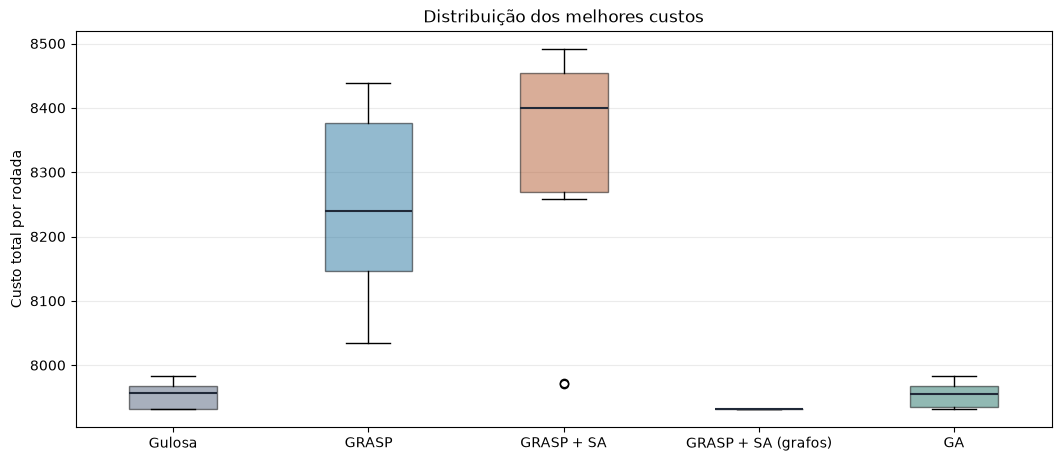

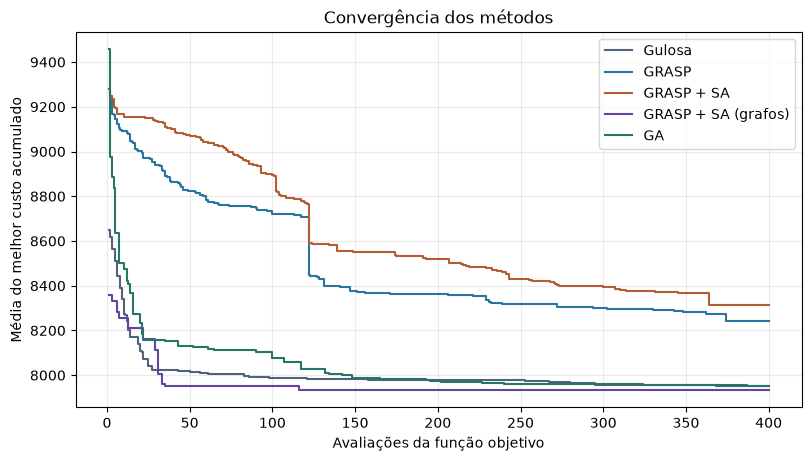

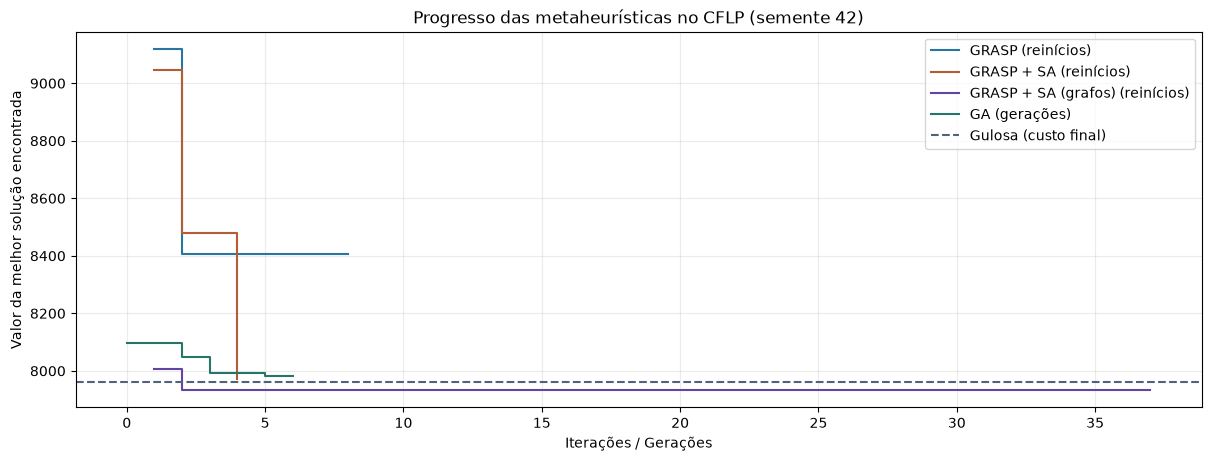

Gráfico salvo em /Users/isadoratebaldi/isadora/isa-flat/cps783-metaheuristics/plots/trabalho/boxplot_custos_grafos.png
Gráfico salvo em /Users/isadoratebaldi/isadora/isa-flat/cps783-metaheuristics/plots/trabalho/convergencia_metodos_grafos.png
Gráfico salvo em /Users/isadoratebaldi/isadora/isa-flat/cps783-metaheuristics/plots/trabalho/progresso_iteracoes_geracoes_grafos.png


In [13]:
DIRETORIO_GRAFICOS.mkdir(parents=True, exist_ok=True)
arquivos_graficos = salvar_graficos_grafos(
    rodadas_grafos, ROTULOS_GRAFOS, DIRETORIO_GRAFICOS
)
for arquivo in arquivos_graficos:
    print(f"Gráfico salvo em {arquivo}")

## 8. Testes

Conferências rápidas: cada método devolve uma solução válida e usa o orçamento inteiro, o GRASP + SA com grafos chega ao ótimo da toy (7.932) em todas as sementes, e os métodos também rodam numa instância aleatória gerada por `Instance.gen_random_instance`.

In [14]:
metodos_testados = (
    executar_gulosa_cflp,
    grasp_cflp,
    grasp_sa_cflp,
    grasp_sa_grafos,
    algoritmo_genetico_cflp,
)

for rodada in rodadas_grafos:
    assert rodada["GRASP + SA com grafos"]["custo"] == 7932

random.seed(0)
instancia_aleatoria = Instance.gen_random_instance(
    n_facilidades=6, n_clientes=15, n_conflitos=5
)
for teste in (instance, instancia_aleatoria):
    for executar in metodos_testados:
        alocacao, abertas, historico = executar(
            teste, seed=42, max_avaliacoes=ORCAMENTO
        )[:3]
        ok, erros = validar_solucao(teste, alocacao, abertas)
        assert ok, erros
        assert len(historico) == ORCAMENTO, (executar.__name__, len(historico))

print("Todos os testes passaram.")

Todos os testes passaram.


## 9. Parâmetros da comparação

Cada coluna mostra os valores usados por um método. **X** indica que o parâmetro não se aplica. Os limites de tentativas, reinícios e passos são tetos. Cada método encerra a rodada assim que atinge o orçamento de avaliações viáveis.

In [15]:
from inspect import signature


def tabela_parametros_grafos(
    instance: Instance, sementes: Sequence[int], orcamento: int
) -> str:
    colunas = {}
    for nome, executar, opcoes in configurar_metodos_grafos(orcamento):
        argumentos = signature(executar).bind(
            instance, seed=sementes[0], max_avaliacoes=orcamento, **opcoes
        )
        argumentos.apply_defaults()
        parametros = argumentos.arguments
        com_sa = executar in (grasp_sa_cflp, grasp_sa_grafos)
        com_vizinho_na_matriz = executar in (grasp_cflp, grasp_sa_cflp)
        com_ga = executar is algoritmo_genetico_cflp

        colunas[nome] = {
            "Rodadas": len(sementes),
            "Avaliações viáveis por rodada": parametros["max_avaliacoes"],
            "Tentativas máximas de construção gulosa": parametros.get("tentativas"),
            "Reinícios máximos": parametros.get("reinicios"),
            "α da lista restrita de candidatos": parametros.get("alpha"),
            "Passos de busca local por reinício": parametros.get(
                "passos_busca", parametros.get("passos_sa")
            ),
            "Tentativas por vizinho da matriz": (
                signature(vizinho_sa_cflp).parameters["max_tentativas"].default
                if com_vizinho_na_matriz
                else None
            ),
            "Temperatura inicial (SA)": parametros["temperatura_inicial"]
            if com_sa
            else None,
            "Temperatura de parada (SA)": TEMPERATURA_MINIMA_SA if com_sa else None,
            "Fator de resfriamento (SA)": parametros["resfriamento"]
            if com_sa
            else None,
            "Tamanho da população (GA)": parametros.get("tamanho_populacao"),
            "Taxa de mutação (GA)": parametros.get("taxa_mutacao"),
            "Probabilidade de cromossomo aleatório por vaga (GA)": (
                CHANCE_IMIGRANTE if com_ga else None
            ),
            "Tentativas máximas de decodificação (GA)": (
                FATOR_LIMITE_TENTATIVAS_GA * parametros["max_avaliacoes"]
                if com_ga
                else None
            ),
        }

    def formatar_valor(valor: int | float | None) -> str:
        if valor is None:
            return "X"
        if isinstance(valor, float):
            return f"{valor:g}".replace(".", ",")
        return str(valor)

    cabecalho = (
        "| Parâmetro | "
        + " | ".join(ROTULOS_GRAFOS[nome] for nome in colunas)
        + " |"
    )
    separador = "| --- |" + " ---: |" * len(colunas)
    linhas = [cabecalho, separador]
    for parametro in next(iter(colunas.values())):
        valores = " | ".join(
            formatar_valor(coluna[parametro]) for coluna in colunas.values()
        )
        linhas.append(f"| {parametro} | {valores} |")
    sementes_texto = ", ".join(map(str, sementes))
    return (
        f"**Sementes usadas em todos os métodos:** {sementes_texto}\n\n"
        + "\n".join(linhas)
    )


tabela_parametros = tabela_parametros_grafos(instance, SEMENTES, ORCAMENTO)
try:
    from IPython.display import Markdown, display
except ImportError:
    print(tabela_parametros)
else:
    display(Markdown(tabela_parametros))


**Sementes usadas em todos os métodos:** 42, 101, 202, 303, 404, 505, 606, 707, 808, 909

| Parâmetro | Gulosa | GRASP | GRASP + SA | GRASP + SA (grafos) | GA |
| --- | ---: | ---: | ---: | ---: | ---: |
| Rodadas | 10 | 10 | 10 | 10 | 10 |
| Avaliações viáveis por rodada | 400 | 400 | 400 | 400 | 400 |
| Tentativas máximas de construção gulosa | 4000 | X | X | X | X |
| Reinícios máximos | X | 4000 | 4000 | 4000 | X |
| α da lista restrita de candidatos | X | 0,35 | 0,35 | 0,35 | X |
| Passos de busca local por reinício | X | 120 | 120 | 80 | X |
| Tentativas por vizinho da matriz | X | 30 | 30 | X | X |
| Temperatura inicial (SA) | X | X | 100 | 100 | X |
| Temperatura de parada (SA) | X | X | 1e-12 | 1e-12 | X |
| Fator de resfriamento (SA) | X | X | 0,97 | 0,97 | X |
| Tamanho da população (GA) | X | X | X | X | 60 |
| Taxa de mutação (GA) | X | X | X | X | 0,3 |
| Probabilidade de cromossomo aleatório por vaga (GA) | X | X | X | X | 0,1 |
| Tentativas máximas de decodificação (GA) | X | X | X | X | 4000 |

## Conclusão

| Método | Como explora e refina as soluções |
|---|---|
| **Gulosa** | Testa ordens e prioridades diferentes a cada tentativa. Cada tentativa constrói uma solução do zero e o método guarda a melhor. |
| **GRASP** | Diversifica ao construir uma nova solução a cada reinício. Em seguida, intensifica com uma busca local que aceita apenas melhorias. |
| **GRASP + SA** | Diversifica na construção e no começo do SA, quando a temperatura está alta. O resfriamento torna a busca progressivamente mais intensificadora dentro de cada reinício. |
| **GRASP + SA com grafos** | Segue o mesmo ciclo do SA. A cada movimento, o algoritmo muda as ligações permitidas e recalcula o fluxo de entregas. |
| **GA** | Combina mecanismos ao longo das gerações. Cruzamento, mutação e cromossomos aleatórios ajudam a explorar, enquanto o torneio favorece indivíduos de menor custo e o elitismo preserva o melhor. |